# Figure S2 - Theoretical coil-to-globule curve for DDX4<sup>[1-245]</sup>

Perets, E. A., Spies, J. A., Cheong, J. H., Shi, L., Asamoto, D. K., Holehouse, A. S., Kim, J. E., Min, W., Neu, J. & Yan, E. C. Y. *Chain collapse, reduced dielectric, and water release drive protein phase separation.* **Biophysical Journal** 125 (2026). doi:[10.1016/j.bpj.2026.07.018](https://doi.org/10.1016/j.bpj.2026.07.018)

**What the figure shows.** A single black curve of the hydrodynamic radius ($R_h$) of the DDX4 N-terminal domain against temperature, with the value at 298 K marked by a red circle. The chain expands monotonically from a compact globule of $R_h \approx 2.2$ nm at low temperature to an expanded coil of $R_h \approx 4.5$ nm at high temperature, passing through the steep part of the transition between roughly 175 K and 275 K. This is the classic coil-to-globule transition expected for a polymer with an upper critical solution temperature (UCST), which is the behaviour DDX4<sup>[1-245]</sup> displays experimentally.

**Why it matters for the paper.** The main text uses this curve twice. First, the red point at 298 K sits at 4.17 nm, in close agreement with the $\langle R_h \rangle = 4.2 \pm 1.1$ nm measured by DLS for monomeric DDX4<sup>[1-245]</sup> under non-phase-separating conditions (Figure 3a). Second, the collapsed low-temperature limit of about 2.2 nm is the value quoted in the discussion of Figure 3 as computational support for the surprisingly compact $\langle R_h \rangle = 1.6 \pm 0.2$ nm state observed by DLS once the sample crosses the binodal. In other words, the simulations independently show that this chain *can* access a globular state of roughly the right size when the solvent quality is reduced.

**An important caveat about the x-axis.** Temperature here is the temperature of the Mpipi-GG coarse-grained model, not a *bona fide* experimental temperature. In these models temperature acts as a parameter that scales the strength of intramolecular interactions relative to thermal energy, so the curve should be read as a solvent-quality axis - low temperature means good intramolecular interactions and a collapsed chain, high temperature means the chain behaves as a self-avoiding walk. The absolute positions on the temperature axis should not be compared with experimental temperatures. This is the caveat given in the published caption and it is worth restating here.

**How it is made.** Coarse-grained molecular dynamics simulations of DDX4<sup>[1-245]</sup> were run in LAMMPS with the Mpipi-GG force field, one simulation per temperature, each generating an ensemble of 6,000 conformers (see *Materials and methods*, "Coarse-grained simulations"). The mean radius of gyration of each ensemble was extracted with SOURSOP; those per-temperature $R_g$ values are the input to this notebook (`data/rgs.txt`). The notebook converts each $R_g$ to an apparent $R_h$ using the empirical relationship of Nygaard *et al.* (2017) and plots the result. There is no trajectory analysis here - all of the expensive work happened upstream.

## What is in this directory

This directory is self-contained: everything needed to regenerate Figure S2 is here, and the notebook only ever reads from paths inside it.

| path | contents |
|------|----------|
| `data/rgs.txt` | mean radius of gyration (Angstroms) of the DDX4<sup>[1-245]</sup> ensemble at each simulated temperature |
| `data/temps.txt` | the corresponding Mpipi-GG model temperatures (K), same ordering, one value per line |
| `data/README.md` | provenance of the two data files |
| `figures/` | output directory; the notebook writes `figure_S2_coil_to_globule.pdf` and `.png` here |

The only dependencies are `numpy` and `matplotlib`.

## Setup

The `matplotlib` settings below are the standard Holehouse lab figure defaults (December 2024 revision). The two `fonttype` settings are the important ones for a publication figure: they force fonts to be embedded as TrueType rather than Type 3, which keeps the text editable if the PDF is later opened in Illustrator or Affinity Designer.

In [1]:
import numpy as np
import matplotlib
import matplotlib.pyplot as plt

# ---------------------------------------------------------------------------
# Holehouse lab figure defaults (December 2024)
# ---------------------------------------------------------------------------

# export PDF/PS fonts as TrueType so text stays editable in Illustrator/Affinity
matplotlib.rcParams['pdf.fonttype'] = 42
matplotlib.rcParams['ps.fonttype'] = 42

# thin axes and lines suited to a small single-column panel
matplotlib.rcParams['axes.linewidth'] = 0.5
matplotlib.rcParams['lines.linewidth'] = 0.8

# tick geometry
matplotlib.rcParams['xtick.major.size'] = 2
matplotlib.rcParams['xtick.minor.size'] = 0.5
matplotlib.rcParams['ytick.major.size'] = 2
matplotlib.rcParams['ytick.minor.size'] = 0.5
matplotlib.rcParams['xtick.major.width'] = 0.375
matplotlib.rcParams['ytick.major.width'] = 0.375
matplotlib.rcParams['xtick.minor.width'] = 0.375
matplotlib.rcParams['ytick.minor.width'] = 0.375
matplotlib.rcParams['xtick.major.pad'] = 1
matplotlib.rcParams['ytick.major.pad'] = 1

# font sizes
matplotlib.rcParams['xtick.labelsize'] = 8
matplotlib.rcParams['ytick.labelsize'] = 8
matplotlib.rcParams['axes.labelsize'] = 10
matplotlib.rcParams['legend.fontsize'] = 8

# The manuscript figures used Arial. The fallbacks let this notebook run
# unchanged on machines without it (matplotlib walks the list in order).
matplotlib.rcParams['font.family'] = 'sans-serif'
matplotlib.rcParams['font.sans-serif'] = ['Arial', 'Helvetica', 'DejaVu Sans']

%matplotlib inline
%config InlineBackend.figure_format = 'retina'

## The data

`data/rgs.txt` and `data/temps.txt` are two parallel single-column files: line $i$ of `rgs.txt` is the mean radius of gyration (in Angstroms) of the 6,000-conformer ensemble simulated at the temperature on line $i$ of `temps.txt`.

Three of the 78 temperatures (9 K, 95 K and 145 K) carry `nan` rather than an $R_g$ value. These are simulations that were not analysed, and they are dropped below. Because the curve is plotted as a single connected line, the two interior gaps at 95 K and 145 K are simply interpolated across; given how smooth the curve is either side of them this is visually invisible.

In [2]:
rg_raw = np.loadtxt('data/rgs.txt')      # mean Rg per temperature, Angstroms
temp_raw = np.loadtxt('data/temps.txt')  # Mpipi-GG model temperature, K

print(f'{len(rg_raw)} temperatures spanning {temp_raw.min():.0f} - {temp_raw.max():.0f} K')
print(f'missing (nan) Rg values at: {temp_raw[np.isnan(rg_raw)]} K')

78 temperatures spanning 9 - 373 K
missing (nan) Rg values at: [  9.  95. 145.] K


## Converting $R_g$ to $R_h$

The simulations report a radius of gyration, but the experiment (DLS) reports a hydrodynamic radius, so a conversion is needed before the two can be compared. For a disordered protein the two are related but not by a single universal constant - the ratio $R_g/R_h$ depends on how expanded the chain is, drifting from around 0.775 for a compact sphere towards roughly 1.5 for a well-solvated coil. This matters enormously here, because the whole point of the figure is that the chain moves between those two regimes.

We therefore use the empirical relationship of Nygaard *et al.* (2017), which parametrises $R_g/R_h$ as a function of both $R_g$ and chain length $N$:

$$\frac{R_g}{R_h} = \frac{\alpha_1 (R_g - \alpha_2 N^{0.33})}{N^{0.60} - N^{0.33}} + \alpha_3$$

with $\alpha_1 = 0.216$, $\alpha_2 = 4.06$ and $\alpha_3 = 0.821$ as fitted in that work, and $N = 245$ for our construct. Inverting gives $R_h = R_g / (R_g/R_h)$.

A note on why *this* approximation. Figure S8 of the paper compares four ways of getting at $R_h$ and makes the point that the choice is not inconsequential: the Kirkwood-Riseman approximation reproduces the PFG-NMR value of Brady *et al.* (3.16 nm), whereas the Nygaard approximation reproduces our DLS value (4.2 nm), for one and the same STARLING ensemble. Since this figure exists to be compared against DLS, we use the Nygaard form.

**Why this is written out here rather than imported.** SOURSOP implements exactly this conversion as `SSProtein.get_hydrodynamic_radius(mode='nygaard')`, and the function below is the same arithmetic with the same default parameters. We cannot call it directly, though, because it is a method on a trajectory object: it computes $R_g$ from coordinates and then converts. The input to *this* figure is a text file of 78 scalar per-temperature averages with no trajectory attached, so the conversion is done locally. Everywhere in this repository that an actual ensemble is available, the SOURSOP API is used directly.

> Nygaard, M., Kragelund, B. B., Papaleo, E. & Lindorff-Larsen, K. *An efficient method for estimating the hydrodynamic radius of disordered protein conformations.* **Biophys. J.** 113, 550-557 (2017). doi:[10.1016/j.bpj.2017.06.042](https://doi.org/10.1016/j.bpj.2017.06.042)

In [3]:
def rg2rh(rg: float,
          nres: int = 245,
          alpha1: float = 0.216,
          alpha2: float = 4.06,
          alpha3: float = 0.821) -> float:
    """
    Convert a radius of gyration into an apparent hydrodynamic radius.

    Uses the empirical approximation derived by Nygaard et al. [1] (their
    equation 7), in which the ratio Rg/Rh is itself a function of the radius
    of gyration and the chain length. This length dependence is what allows
    the conversion to remain sensible across a coil-to-globule transition,
    where Rg/Rh is not constant.

    Parameters
    ----------
    rg : float
        Radius of gyration of the chain, in Angstroms.

    nres : int
        Number of residues in the chain. Default = 245, the length of the
        DDX4[1-245] construct used throughout this paper.

    alpha1 : float
        First fit parameter in equation (7) of Nygaard et al. Default = 0.216.

    alpha2 : float
        Second fit parameter in equation (7) of Nygaard et al. Default = 4.06.

    alpha3 : float
        Third fit parameter in equation (7) of Nygaard et al. Default = 0.821.

    Returns
    -------
    float
        The inferred hydrodynamic radius, in the same units as `rg`.

    References
    ----------
    [1] Nygaard, M., B. B. Kragelund, E. Papaleo, and K. Lindorff-Larsen.
        2017. An Efficient Method for Estimating the Hydrodynamic Radius of
        Disordered Protein Conformations. Biophys. J. 113:550-557.
    """

    # precompute the two chain-length terms
    N_033 = np.power(nres, 0.33)
    N_060 = np.power(nres, 0.60)

    rg_over_rh = ((alpha1 * (rg - alpha2 * N_033)) / (N_060 - N_033)) + alpha3

    return (1 / rg_over_rh) * rg

Drop the missing values and convert. We also convert Angstroms to nanometres here, since the published axis is in nm.

In [4]:
valid = ~np.isnan(rg_raw)

temp = temp_raw[valid]
rh = np.array([rg2rh(value) for value in rg_raw[valid]]) / 10.0   # Angstroms -> nm

# The published panel starts at 50 K. The two lowest temperatures simulated
# (9 K and 14 K) sit far below the rest of the temperature series - 9 K has no
# Rg value at all, and dropping the isolated 14 K point avoids a long
# interpolated segment across the 14 -> 50 K gap. This reproduces the
# published figure; see the note at the end of the notebook.
temp = temp[1:]
rh = rh[1:]

print(f'{len(temp)} points plotted, spanning {temp.min():.0f} - {temp.max():.0f} K')

74 points plotted, spanning 50 - 373 K


## The two numbers the main text quotes

Before plotting, pull out the two values the paper actually cites: the room-temperature point that is compared against the DLS measurement of the expanded monomer, and the low-temperature plateau that is compared against the collapsed state.

In [5]:
rh_298 = rh[temp == 298][0]

print(f'Rh at 298 K            : {rh_298:.2f} nm   (DLS, non-phase-separating: 4.2 +/- 1.1 nm)')
print(f'Rh at {temp.min():.0f} K (collapsed) : {rh.min():.2f} nm   (DLS, phase-separating: 1.6 +/- 0.2 nm)')
print(f'Rh at {temp.max():.0f} K (expanded)  : {rh.max():.2f} nm')
print(f'total expansion        : {rh.max() / rh.min():.2f}-fold')

Rh at 298 K            : 4.17 nm   (DLS, non-phase-separating: 4.2 +/- 1.1 nm)
Rh at 50 K (collapsed) : 2.16 nm   (DLS, phase-separating: 1.6 +/- 0.2 nm)
Rh at 373 K (expanded)  : 4.54 nm
total expansion        : 2.10-fold


## The figure

A single panel, 3.5 x 2.5 inches, sized for the SI page. The red marker is the 298 K point.

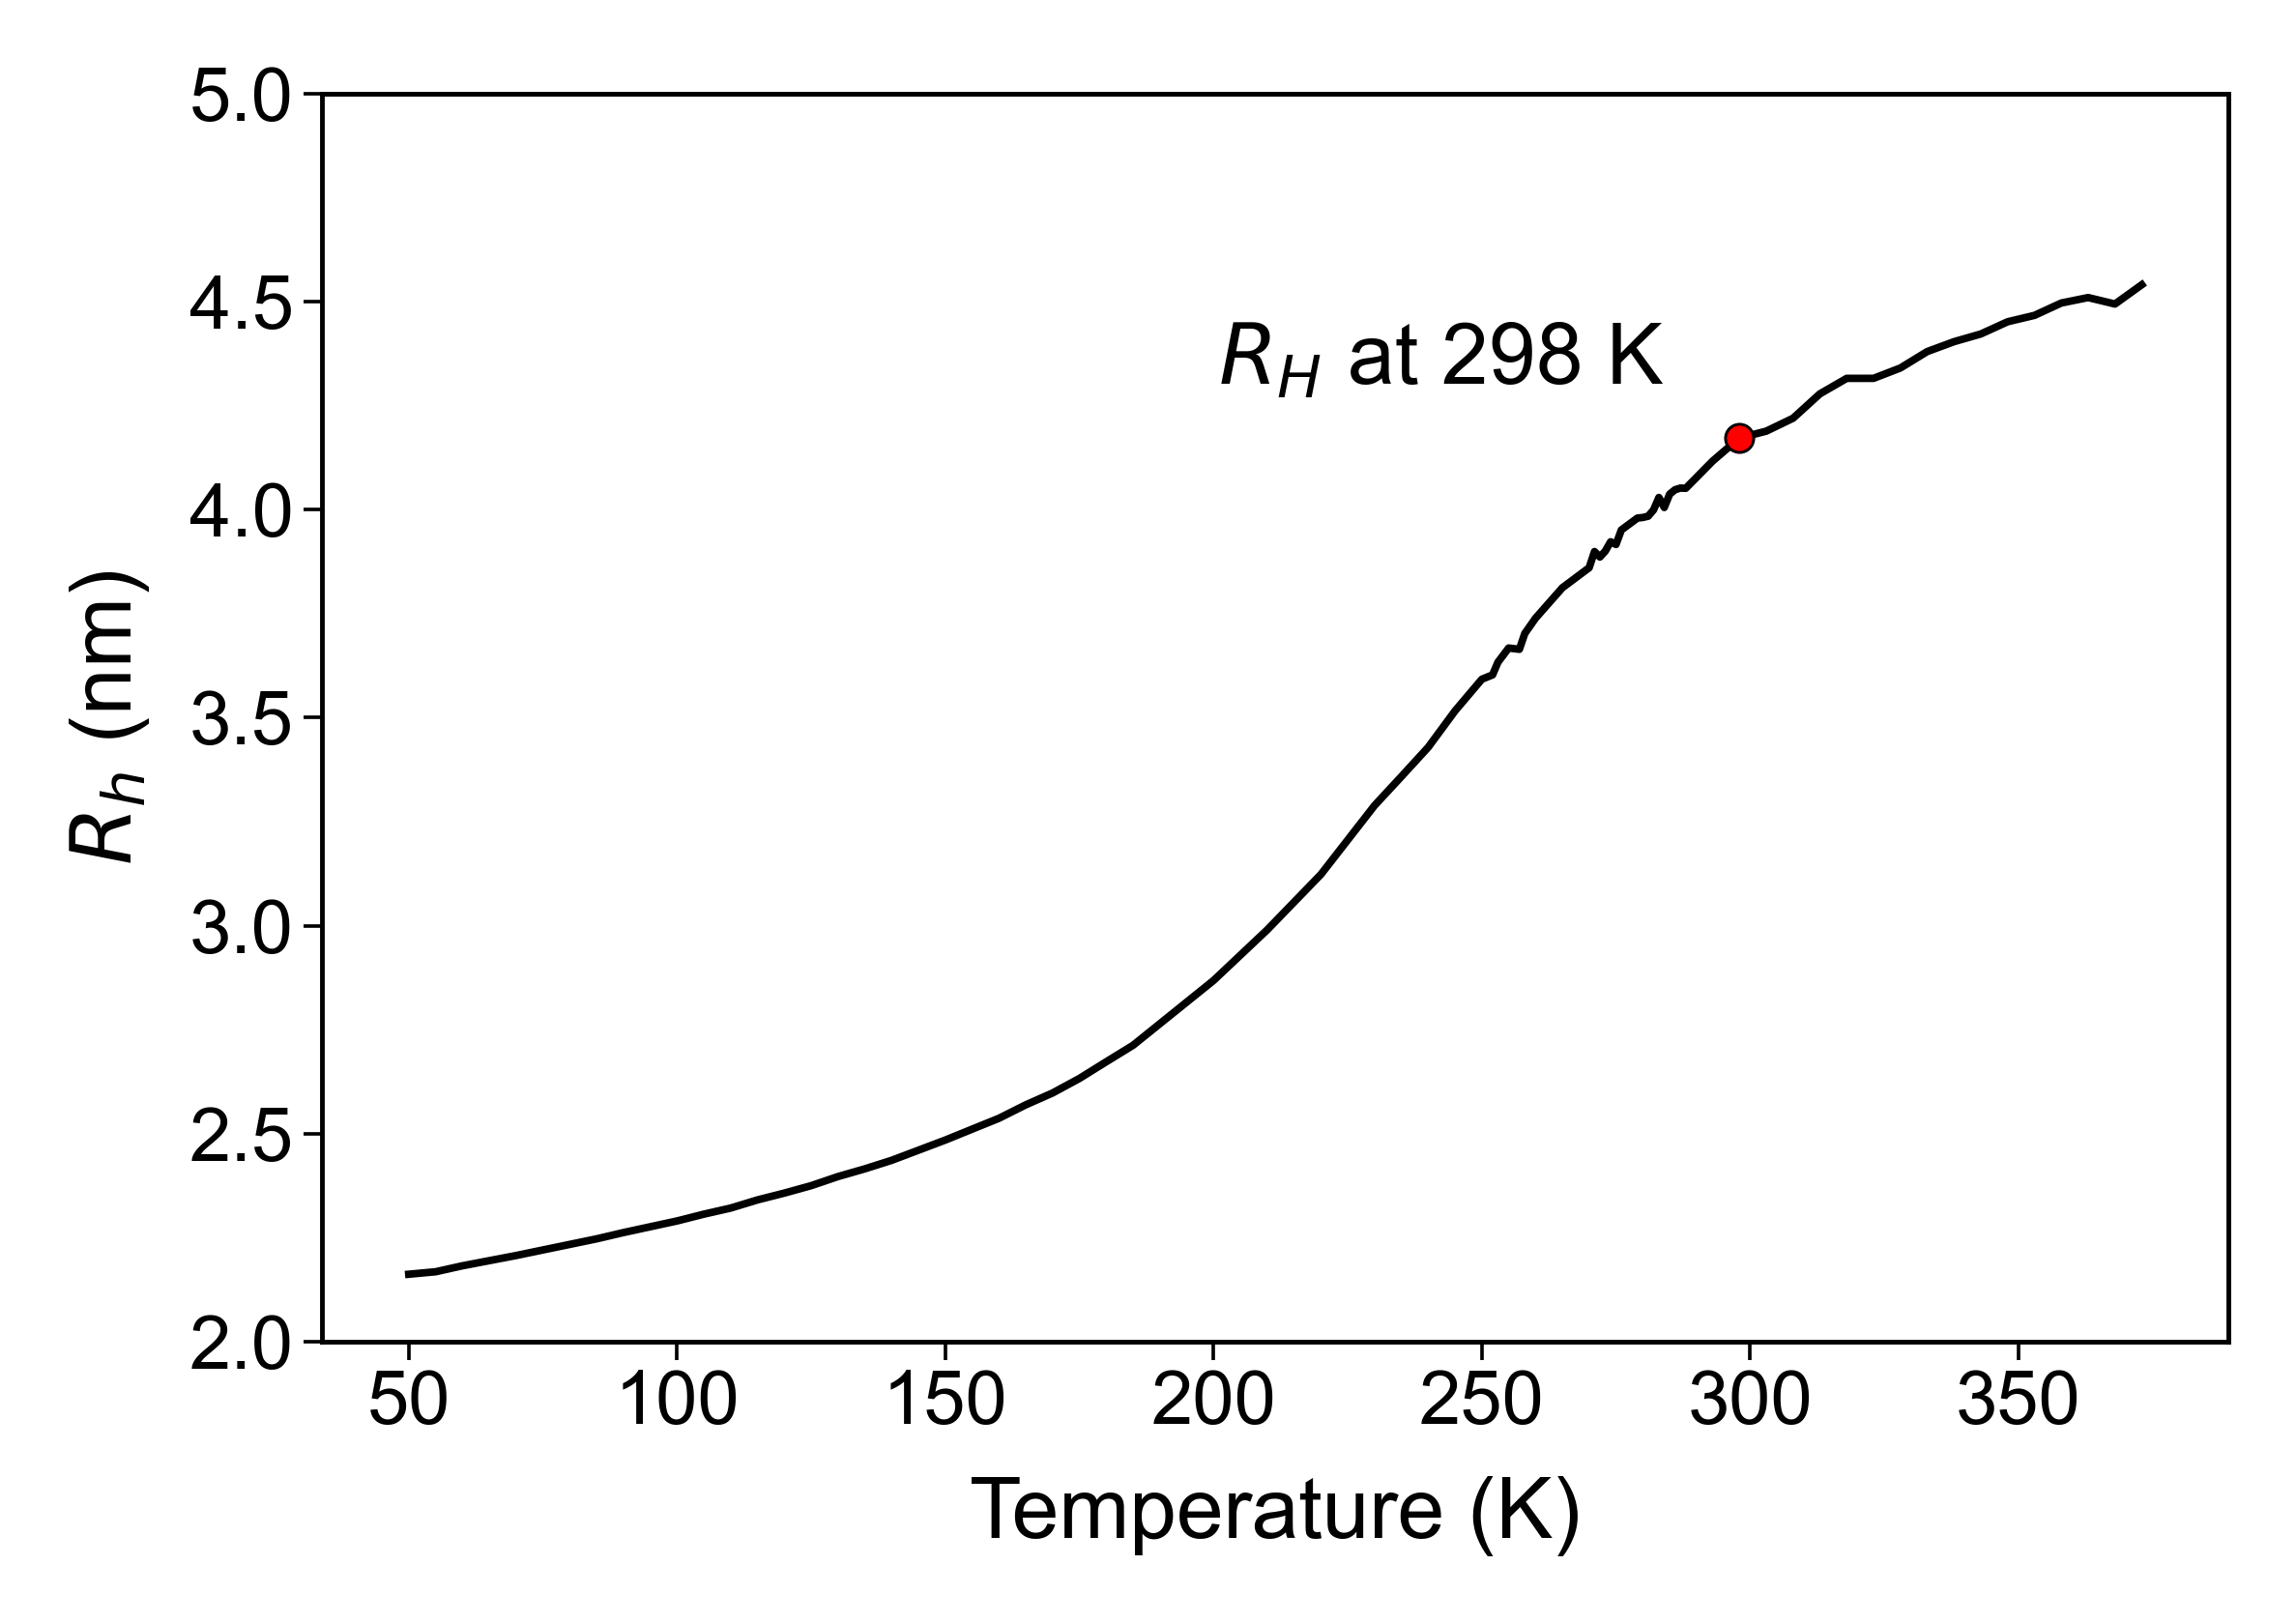

In [6]:
fig = plt.figure(figsize=(3.5, 2.5), dpi=350)
ax = plt.gca()

# the coil-to-globule curve
ax.plot(temp, rh, color='k')

# highlight room temperature
ax.plot(298, rh_298, 'ok', ms=3, mew=0.3, mfc='r')
ax.annotate(r'$R_H$ at 298 K',
            xy=(298, rh_298), xytext=(-8, 4),
            textcoords='offset points',
            ha='right', va='bottom', fontsize=9)

ax.set_xlabel('Temperature (K)', fontsize=9)
ax.set_ylabel('$R_h$ (nm)', fontsize=9)
ax.set_ylim([2, 5])

plt.tight_layout()
plt.savefig('figures/figure_S2_coil_to_globule.pdf')
plt.savefig('figures/figure_S2_coil_to_globule.png', dpi=350)
plt.show()

## Differences from the published figure

* **Typesetting.** The published panel was restyled in a vector graphics editor after export - larger axis labels and tick labels, heavier axis lines, and a larger red marker. The underlying curve and data are identical; this notebook reproduces the raw export.
* **The 298 K annotation.** The `$R_H$ at 298 K` label was added by hand to the published figure. It is drawn by `ax.annotate` here so that the notebook produces a complete, self-explanatory panel.
* **Font fallbacks.** The original set `font.family` to Arial directly. Here Arial is first in a fallback list, so the notebook runs without warnings on machines that do not have it. If you have Arial installed the output is unchanged.
* **The dropped 14 K point.** The original notebook indexed the arrays as `[1:]` after removing NaNs, which discards the 14 K point ($R_h = 2.26$ nm) as well as the NaN at 9 K. We keep that behaviour so the panel matches the published one; including it would add a single point at the far left and stretch the x-axis down to 14 K without changing the shape of the transition.

## What is *not* here

The upstream coarse-grained simulations themselves - LAMMPS input decks, force field files and trajectories - are not included in this directory. `data/rgs.txt` is the reduced output of that pipeline (one mean $R_g$ per temperature), and it is the true input to the figure. See `data/README.md` for the simulation parameters as reported in the paper's *Materials and methods*.